# Modelo original: Band-Likelihood Gradient Boosting

In [1]:
import sys, json, warnings, pickle
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from myst_nb import glue
from src import estilo
from src.estilo import RIO, SED, CAU, ALE, NEU
from src.config import RESULTADOS, DATOS_PROC, SEED

## Motivación

Los modelos benchmark del capítulo anterior reciben como objetivo una etiqueta binaria: el día
*t* + 15 estuvo o no dentro de la banda de descarga efectiva. Esa etiqueta resulta de aplicar
una condición de intervalo a una variable continua que también se observa, el caudal
$Q_{t+15}$, y al binarizarla se descarta información. Dos días negativos son indistinguibles
para un clasificador aunque uno haya quedado a 50 m³/s del límite y el otro a 5.000 m³/s, y dos
días positivos valen lo mismo aunque uno haya caído en el centro de la banda y el otro en su
borde. Con un tamaño efectivo de muestra reducido por la autocorrelación, esa pérdida de
información se traduce en varianza.

La alternativa habitual en hidrología, predecir el caudal y luego comparar con los límites,
resuelve el problema solo a medias. Un regresor de mínimos cuadrados estima la media
condicional, no la probabilidad de un intervalo; la probabilidad de banda exige además la
dispersión condicional, que varía con el estado del río (la incertidumbre a quince días es
mayor en el ascenso de una crecida que en un estiaje estable), y un modelo ajustado solo para
el caudal no tiene incentivo para ser preciso justamente en la región de los límites, que es
la que decide la clasificación.

El modelo propuesto, **Band-Likelihood Gradient Boosting (BLGB)**, combina ambas fuentes de
supervisión en una sola función objetivo: modela la distribución condicional completa del
caudal futuro, con media y dispersión dependientes de las condiciones actuales, y la ajusta con
una pérdida que pondera explícitamente el acierto sobre el evento de interés.

## Formulación

Sea $Q^{\text{ref}}_i > 0$ el caudal observado en el instante de la predicción y
$z_i = \log(Q_{i,t+h}/Q^{\text{ref}}_i)$ el cambio logarítmico a horizonte $h$. La banda
$[L, U]$ se traslada al mismo espacio con límites propios de cada observación,

$$
l_i = \log\frac{L}{Q^{\text{ref}}_i}, \qquad u_i = \log\frac{U}{Q^{\text{ref}}_i}.
$$ (eq-limites)

El modelo supone $z_i \mid x_i \sim \mathcal{N}(\mu(x_i), \sigma(x_i)^2)$ y define la
probabilidad de la clase positiva como la masa de esa distribución dentro de la banda,

$$
p_i = \Phi\!\left(b_i\right) - \Phi\!\left(a_i\right), \qquad
a_i = \frac{l_i - \mu_i}{\sigma_i}, \quad b_i = \frac{u_i - \mu_i}{\sigma_i}.
$$ (eq-prob)

La media $\mu$ y el logaritmo de la dispersión $s = \log \sigma$ son dos ensambles aditivos de
árboles de regresión, $\mu(x) = \mu_0 + \sum_t \eta_t f^{\mu}_t(x)$ y
$s(x) = s_0 + \sum_t \eta_t f^{s}_t(x)$. Trabajar con $\log(Q_{t+h}/Q^{\text{ref}})$ en lugar del
caudal tiene dos ventajas: el cambio relativo es aproximadamente simétrico y estacionario, y la
dependencia de la banda respecto del estado actual queda absorbida por los límites
{eq}`eq-limites`, de modo que los árboles solo deben aprender la dinámica del cambio.

La pérdida empírica combina la entropía cruzada del evento y la log-verosimilitud gaussiana
del caudal futuro, ponderada por $\lambda \geq 0$:

$$
\mathcal{L}(\mu, s) = \frac{1}{n}\sum_{i=1}^{n}\Big[-y_i\log p_i - (1-y_i)\log(1-p_i)\Big]
+ \lambda\,\frac{1}{n}\sum_{i=1}^{n}\Big[\tfrac{1}{2} r_i^2 + s_i\Big], \qquad r_i = \frac{z_i-\mu_i}{\sigma_i}.
$$ (eq-perdida)

El primer término es la pérdida de la tarea y el segundo aporta la supervisión continua. Con
$\lambda = 0$ el modelo es un clasificador de banda que solo usa la etiqueta; con
$\lambda \to \infty$ se reduce a una regresión distribucional del caudal seguida de la
integración {eq}`eq-prob`, es decir, al enfoque de dos etapas.

## Gradientes y hessianos

El boosting de segundo orden requiere, para cada observación, el gradiente y una aproximación
positiva del hessiano de la pérdida respecto de $\mu_i$ y $s_i$. Con $\varphi$ la densidad
normal estándar, la derivada de la probabilidad de banda es

$$
\frac{\partial p}{\partial \mu} = \frac{\varphi(a) - \varphi(b)}{\sigma}, \qquad
\frac{\partial p}{\partial s} = a\,\varphi(a) - b\,\varphi(b),
$$ (eq-dp)

la segunda porque $\partial a/\partial s = -a$ y $\partial b/\partial s = -b$ cuando
$s = \log\sigma$. Por la regla de la cadena y
$\partial \ell_{\text{BCE}}/\partial p = (p - y)/[p(1-p)]$, el término de la tarea aporta

$$
g^{\text{BCE}}_\theta = \frac{p-y}{p(1-p)}\,\frac{\partial p}{\partial \theta}, \qquad
h^{\text{BCE}}_\theta = \frac{1}{p(1-p)}\left(\frac{\partial p}{\partial \theta}\right)^2,
\qquad \theta \in \{\mu, s\},
$$ (eq-gbce)

donde el hessiano es la aproximación de Gauss-Newton, igual a la información de Fisher del
modelo de Bernoulli y siempre no negativa. El término gaussiano aporta

$$
g^{\text{N}}_\mu = -\frac{r}{\sigma}, \quad h^{\text{N}}_\mu = \frac{1}{\sigma^2}, \qquad
g^{\text{N}}_s = 1 - r^2, \quad h^{\text{N}}_s = 2,
$$ (eq-gnll)

con $h^{\text{N}}_s = 2$ igual a la información de Fisher del parámetro de escala logarítmica.
El gradiente total es $g = g^{\text{BCE}} + \lambda g^{\text{N}}$ y el hessiano
$h = h^{\text{BCE}} + \lambda h^{\text{N}}$. La prueba unitaria
`test_gradientes_analiticos_coinciden_con_diferencias_finitas` verifica {eq}`eq-gbce` y
{eq}`eq-gnll` contra diferencias finitas centrales con tolerancia relativa de $10^{-4}$.

## Árboles de segundo orden por histogramas

Cada ronda ajusta un árbol para $\mu$ y otro para $s$. Las variables se discretizan una sola
vez en $B = 64$ bins por cuantiles del entrenamiento, y los árboles crecen por niveles: para
cada nodo de un nivel se acumulan los gradientes y hessianos por variable y bin con una sola
llamada a `np.bincount`, y la mejor división maximiza la ganancia de segundo orden

$$
\Delta = \frac{1}{2}\left[\frac{G_L^2}{H_L+\lambda_h} + \frac{G_R^2}{H_R+\lambda_h} - \frac{G^2}{H+\lambda_h}\right] - \gamma,
$$ (eq-ganancia)

sujeta a que cada hijo acumule un hessiano mínimo. El valor de cada hoja es el paso de Newton
regularizado $w_j = -G_j/(H_j + \lambda_h)$, de modo que, sobre los datos de la ronda, la
derivada direccional de la pérdida a lo largo del árbol es
$\sum_j G_j w_j = -\sum_j G_j^2/(H_j+\lambda_h) \leq 0$: cada árbol es una dirección de
descenso. Los faltantes se reemplazan por la mediana de entrenamiento antes de discretizar.

## Pseudocódigo

```text
Algoritmo BLGB
Entrada: X ∈ ℝ^{n×p}, y ∈ {0,1}^n, caudal futuro q ∈ ℝ₊^n, referencia Q_ref ∈ ℝ₊^n,
         banda [L, U], peso λ ≥ 0, tasa η, rondas T, profundidad d, paciencia P,
         cotas σ_min < σ_max, fracción de validación ρ
Salida:  ensambles F_μ, F_s

 1  z_i ← log(q_i / Q_ref,i);  l_i ← log(L / Q_ref,i);  u_i ← log(U / Q_ref,i)
 2  Discretizar cada columna de X en B bins por cuantiles (ajustados con X)
 3  Separar el último ρ·n cronológico como validación V; el resto es A
 4  μ_i ← media(z_A);  s_i ← clip(log desv(z_A), log σ_min, log σ_max)
 5  para t = 1, …, T:
 6      (g_μ, h_μ, g_s, h_s) ← gradientes de ℒ en (μ, s) sobre una submuestra de A
 7      f_μ ← ÁrbolNewton(X, g_μ, h_μ, d);   f_s ← ÁrbolNewton(X, g_s, h_s, d)
 8      η_t ← η
 9      repetir hasta 8 veces:
10          si ℒ_A(μ + η_t f_μ, clip(s + η_t f_s)) ≤ ℒ_A(μ, s) + c·η_t·min(∇ℒ_Aᵀf, 0):  aceptar
11          si no: η_t ← η_t / 2
12      si no se aceptó: terminar
13      μ ← μ + η_t f_μ;   s ← clip(s + η_t f_s)
14      si la entropía cruzada en V no mejora en P rondas: terminar
15  Truncar en la ronda t* de mejor validación; reentrenar con A ∪ V durante t* rondas
16  devolver F_μ, F_s
```

## Propiedades teóricas

(teo-propia-ref)=
### Teorema 1. La pérdida híbrida es una regla de puntuación estrictamente propia

**Enunciado.** Sea $G$ la distribución verdadera de $z$ condicionada a $x$, con densidad $g$, y
sea $F$ cualquier distribución predictiva con densidad $f$. Para una banda fija $B=[l,u]$
defínase la puntuación
$S_\lambda(F, z) = -\mathbb{1}\{z\in B\}\log F(B) - \mathbb{1}\{z\notin B\}\log(1-F(B)) - \lambda\log f(z)$.
Si $\lambda > 0$, entonces $\mathbb{E}_{G}[S_\lambda(F, Z)] \geq \mathbb{E}_{G}[S_\lambda(G, Z)]$, con
igualdad si y solo si $f = g$ casi en todas partes.

**Demostración.** La esperanza se descompone en

$$
\mathbb{E}_G[S_\lambda(F,Z)] = \underbrace{-G(B)\log F(B) - (1-G(B))\log(1-F(B))}_{\text{(i)}}
\; \underbrace{- \lambda\,\mathbb{E}_G[\log f(Z)]}_{\text{(ii)}}.
$$

El término (i) es la entropía cruzada entre dos distribuciones de Bernoulli de parámetros
$G(B)$ y $F(B)$; por la desigualdad de Gibbs es mayor o igual que la entropía de
$\text{Bernoulli}(G(B))$, con igualdad si y solo si $F(B) = G(B)$. El término (ii) satisface
$-\mathbb{E}_G[\log f] = -\mathbb{E}_G[\log g] + \mathrm{KL}(G\,\|\,F) \geq -\mathbb{E}_G[\log g]$, con
igualdad si y solo si $f = g$ casi en todas partes. Sumando, la esperanza es mínima en $F = G$.
Si $\mathbb{E}_G[S_\lambda(F,Z)] = \mathbb{E}_G[S_\lambda(G,Z)]$, como ambos términos alcanzan su
mínimo en $G$ y la suma es igual, cada uno debe alcanzarlo; en particular
$\lambda\,\mathrm{KL}(G\|F) = 0$ y, por ser $\lambda>0$, $f = g$ casi en todas partes. $\blacksquare$

El teorema tiene una consecuencia práctica. El término de la tarea por sí solo es propio pero
no estrictamente propio respecto de la distribución completa: cualquier $F$ con la misma masa
en la banda lo minimiza, de modo que no identifica $\mu$ ni $\sigma$ y deja al modelo con
muchos grados de libertad sin información para fijarlos. El término gaussiano restituye la
identificabilidad y, por tanto, la consistencia del estimador en una clase de funciones
suficientemente rica {cite}`gneiting2007`. A la inversa, cuando el modelo gaussiano está mal
especificado (colas o asimetría distintas de las reales), el minimizador de la verosimilitud
sola no coincide en general con la masa verdadera de la banda; el término de la tarea corrige
ese sesgo en la región que decide la clasificación. El peso $\lambda$ regula ese equilibrio y
se elige por validación anidada.

(teo-descenso-ref)=
### Teorema 2. Descenso monótono y terminación

**Enunciado.** Con $\sigma \in [\sigma_{\min}, \sigma_{\max}]$, la sucesión de pérdidas de
entrenamiento $\mathcal{L}_t$ generada por el algoritmo es no creciente y converge, y el
algoritmo termina en a lo sumo $T$ rondas.

**Demostración.** El término de entropía cruzada es no negativo. En el término gaussiano,
$\tfrac12 r^2 + s \geq s \geq \log\sigma_{\min}$, de modo que
$\mathcal{L} \geq \lambda\log\sigma_{\min} > -\infty$: la pérdida está acotada inferiormente
gracias a la cota de $\sigma$ (sin ella, $s \to -\infty$ en observaciones con residuo nulo haría
divergir la verosimilitud). En cada ronda, el paso se acepta solo si cumple la condición de
Armijo, $\mathcal{L}_{t} \leq \mathcal{L}_{t-1} + c\,\eta_t \min(\nabla\mathcal{L}^\top f, 0) \leq
\mathcal{L}_{t-1}$ {cite}`armijo1966`; si ningún paso la cumple, el algoritmo se detiene sin
modificar el modelo. Por tanto $\{\mathcal{L}_t\}$ es no creciente y acotada inferiormente, y
converge por el teorema de la convergencia monótona. La terminación es inmediata porque el
número de rondas está acotado por $T$ y cada ronda ejecuta a lo sumo ocho evaluaciones de la
búsqueda lineal. $\blacksquare$

La garantía es deliberadamente modesta: asegura estabilidad numérica y monotonía, no
convergencia a un mínimo global, que no cabe esperar en un problema no convexo. Su valor
práctico se mide en la ablación: sin la búsqueda lineal, el paso fijo puede aumentar la pérdida
cuando los gradientes de la submuestra no representan bien los del conjunto completo, lo que
ocurre con frecuencia en los bordes de la banda, donde $p(1-p)$ es pequeño y la entropía
cruzada tiene curvatura alta. La prueba `test_descenso_monotono_de_la_perdida` verifica la
monotonía en cada ronda.

(prop-complejidad-ref)=
### Proposición 1. Complejidad

Sea $n$ el número de observaciones, $p$ el de variables, $k = \lceil c\,p\rceil$ las columnas
muestreadas por ronda, $B$ los bins, $d$ la profundidad y $T$ las rondas. La discretización
cuesta $O(np\log n)$ una vez. En cada nivel de un árbol, el histograma conjunto de todos los
nodos cuesta $O(nk)$ y la búsqueda de la división, $O(m k B)$ con $m \leq 2^{d}$ nodos; un
árbol cuesta $O(d(nk + 2^d kB))$. Cada ronda construye dos árboles, evalúa los gradientes en
$O(n)$ y la búsqueda lineal en $O(n)$ por intento, de modo que el entrenamiento cuesta

$$
O\!\left(np\log n + T\,d\,(nk + 2^{d}kB)\right),
$$ (eq-complejidad)

lineal en $n$ para $d$ y $B$ fijos. La inferencia de una observación cuesta $O(p\log B)$ por la
discretización y $O(Td)$ por el recorrido de los $2T$ árboles. La memoria es $O(np)$ bytes, por
almacenar la matriz discretizada en `uint8`, más $O(T2^d)$ por los árboles. El contraste con el
tiempo empírico al variar $n$ se presenta en la sección de optimización computacional.

## Implementación

La implementación completa está en `src/original_model.py`. La clase
`BandLikelihoodBoosting` hereda de `BaseEstimator` y `ClassifierMixin`, expone `fit`,
`predict_proba` y `predict`, y añade `predict_distribucion`, que devuelve la mediana y un
intervalo de predicción del caudal futuro: el dashboard lo usa para mostrar, junto con la
probabilidad de banda, el rango de caudales esperado. Las dependencias numéricas se limitan a
numpy y a `scipy.special.ndtr` para la función de distribución normal.

Los bloques siguientes muestran el núcleo del algoritmo tal como está en
`src/original_model.py`. El primero contiene la probabilidad de banda {eq}`eq-prob`, la pérdida
híbrida {eq}`eq-perdida` y los gradientes y hessianos {eq}`eq-gbce` y {eq}`eq-gnll`.

In [2]:
import inspect
from IPython.display import Code
from src import original_model as om
Code("\n\n".join(inspect.getsource(f) for f in (om.probabilidad_banda, om.perdida_hibrida, om.gradientes)),
     language="python")

def probabilidad_banda(mu, s, l, u):
    """p = Φ((u−μ)/σ) − Φ((l−μ)/σ) y los términos intermedios."""
    sig = np.exp(s)
    a, b = (l - mu) / sig, (u - mu) / sig
    p = np.clip(ndtr(b) - ndtr(a), _EPS, 1 - _EPS)
    return p, a, b, sig


def perdida_hibrida(mu, s, l, u, y, z, lam):
    """Pérdida media: entropía cruzada de la banda + λ · NLL gaussiana del cambio logarítmico."""
    p, _, _, sig = probabilidad_banda(mu, s, l, u)
    bce = -(y * np.log(p) + (1 - y) * np.log1p(-p))
    if z is None or lam == 0:
        return float(bce.mean())
    r = (z - mu) / sig
    return float(bce.mean() + lam * (0.5 * r * r + s).mean())


def gradientes(mu, s, l, u, y, z, lam):
    """Gradientes y hessianos (Gauss-Newton) respecto de μ y s = log σ.

    Término de banda, con dp/dμ = (φ(a) − φ(b))/σ y dp/ds = aφ(a) − bφ(b):
        g = (p − y)/(p(1 − p)) · dp/dθ,   h = (dp/dθ)²/(p(1 − p)).
    Término gaussiano (información de Fisher):
        g_μ = −(z − μ)/σ²,  h_μ = 1/σ²,   g_s = 1 − r²,  h_s = 2.
    """
    p, a, b, sig = probabilidad_banda(mu, s, l, u)
    pa, pb = _phi(a), _phi(b)
    dp_mu = (pa - pb) / sig
    dp_s = a * pa - b * pb
    w = 1.0 / (p * (1 - p))
    g_mu, g_s = (p - y) * w * dp_mu, (p - y) * w * dp_s
    h_mu, h_s = w * dp_mu ** 2, w * dp_s ** 2
    if z is not None and lam > 0:
        r = (z - mu) / sig
        g_mu = g_mu - lam * r / sig
        h_mu = h_mu + lam / sig ** 2
        g_s = g_s + lam * (1 - r * r)
        h_s = h_s + 2 * lam
    return g_mu, h_mu + 1e-9, g_s, h_s + 1e-9

El segundo construye cada árbol por niveles: acumula gradientes y hessianos por bin con
`np.bincount`, evalúa la ganancia {eq}`eq-ganancia` en todos los cortes y asigna a cada hoja el
paso de Newton regularizado.

In [3]:
Code(inspect.getsource(om.construir_arbol), language="python")

def construir_arbol(Xb: np.ndarray, g: np.ndarray, h: np.ndarray, n_bins: int, profundidad: int,
                    min_hess: float, reg_lambda: float, gamma: float,
                    columnas: np.ndarray) -> _Arbol:
    """Crece un árbol por niveles maximizando la ganancia de segundo orden.

    Para un nodo con sumas (G, H) dividido en (G_L, H_L) y (G_R, H_R):

        ganancia = ½ [G_L²/(H_L+λ) + G_R²/(H_R+λ) − G²/(H+λ)] − γ,

    y el valor de cada hoja es −G/(H+λ), el paso de Newton regularizado. Los histogramas de
    todos los nodos de un nivel se calculan con una sola llamada a ``np.bincount``.

    Complejidad por nivel: O(n·k + m·k·B), con k columnas, B bins y m nodos del nivel.
    """
    n = len(g)
    k = len(columnas)
    sub = Xb[:, columnas].astype(np.int64)            # (n, k)
    offs = (np.arange(k, dtype=np.int64) * n_bins)[None, :]
    arbol = _Arbol()
    raiz = arbol._nuevo(-g.sum() / (h.sum() + reg_lambda))
    nodo_de = np.zeros(n, dtype=np.int64)              # nodo actual de cada observación
    frontera = [raiz]
    for _ in range(profundidad):
        if not frontera:
            break
        pos = {nd: j for j, nd in enumerate(frontera)}
        local = np.full(len(arbol.valor), -1, dtype=np.int64)
        for nd, j in pos.items():
            local[nd] = j
        loc = local[nodo_de]
        vivos = loc >= 0
        if not vivos.any():
            break
        m = len(frontera)
        idx = (loc[vivos, None] * (k * n_bins) + offs + sub[vivos]).ravel()
        tam = m * k * n_bins
        G = np.bincount(idx, weights=np.repeat(g[vivos], k), minlength=tam).reshape(m, k, n_bins)
        H = np.bincount(idx, weights=np.repeat(h[vivos], k), minlength=tam).reshape(m, k, n_bins)
        GL, HL = np.cumsum(G, axis=2), np.cumsum(H, axis=2)
        Gt, Ht = GL[:, :, -1:], HL[:, :, -1:]
        GR, HR = Gt - GL, Ht - HL
        with np.errstate(divide="ignore", invalid="ignore"):
            ganancia = 0.5 * (GL ** 2 / (HL + reg_lambda) + GR ** 2 / (HR + reg_lambda)
                              - Gt ** 2 / (Ht + reg_lambda)) - gamma
        ganancia[(HL < min_hess) | (HR < min_hess)] = -np.inf
        ganancia[:, :, -1] = -np.inf                   # el último bin no separa nada
        plano = ganancia.reshape(m, -1)
        mejor = plano.argmax(axis=1)
        nueva_frontera = []
        for j, nd in enumerate(frontera):
            gmax = plano[j, mejor[j]]
            if not np.isfinite(gmax) or gmax <= 0:
                continue
            f_loc, b = divmod(int(mejor[j]), n_bins)
            gl, hl = GL[j, f_loc, b], HL[j, f_loc, b]
            gr, hr = GR[j, f_loc, b], HR[j, f_loc, b]
            iz = arbol._nuevo(-gl / (hl + reg_lambda))
            de = arbol._nuevo(-gr / (hr + reg_lambda))
            arbol.feat[nd], arbol.umbral[nd] = int(columnas[f_loc]), b
            arbol.izq[nd], arbol.der[nd] = iz, de
            en_nodo = nodo_de == nd
            a_izq = en_nodo & (Xb[:, columnas[f_loc]] <= b)
            nodo_de[en_nodo] = de
            nodo_de[a_izq] = iz
            nueva_frontera += [iz, de]
        frontera = nueva_frontera
    return arbol.congelar()

El tercero es el ciclo de boosting: en cada ronda ajusta un árbol para μ y otro para s, aplica la
búsqueda lineal de Armijo del {ref}`teorema 2 <teo-descenso-ref>` y controla la parada temprana
con la entropía cruzada del tramo cronológico de validación.

In [4]:
Code(inspect.getsource(om.BandLikelihoodBoosting._boosting), language="python")

def _boosting(self, Xb, y, z, l, u, idx_tr, idx_va, n_rondas):
        rng = np.random.default_rng(self.random_state)
        lam = self.lambda_hibrido if z is not None else 0.0
        p_feat = Xb.shape[1]
        ztr = None if z is None else z[idx_tr]
        if z is not None:
            mu0, s0 = float(np.mean(ztr)), float(np.log(max(np.std(ztr), self.sigma_min)))
        else:
            # Sin caudal futuro: σ inicial unitaria y μ centrado en la banda
            mu0, s0 = float(np.mean((l[idx_tr] + u[idx_tr]) / 2)), 0.0
        s0 = float(self._clip_s(np.array([s0]))[0])
        mu = np.full(len(y), mu0)
        s = np.full(len(y), s0)
        arboles_mu, arboles_s, pasos, historial = [], [], [], []
        mejor_va, mejor_iter, sin_mejora = np.inf, 0, 0

        def L(idx, m, ss):
            return perdida_hibrida(m[idx], ss[idx], l[idx], u[idx], y[idx],
                                   None if z is None else z[idx], lam)

        perdida_actual = L(idx_tr, mu, s)
        for t in range(n_rondas):
            filas = idx_tr
            if self.submuestreo < 1:
                filas = np.sort(rng.choice(idx_tr, max(2, int(len(idx_tr) * self.submuestreo)),
                                           replace=False))
            cols = np.sort(rng.choice(p_feat, max(1, int(round(p_feat * self.columnas))),
                                      replace=False))
            g_mu, h_mu, g_s, h_s = gradientes(mu[filas], s[filas], l[filas], u[filas], y[filas],
                                              None if z is None else z[filas], lam)
            a_mu = construir_arbol(Xb[filas], g_mu, h_mu, self.n_bins, self.profundidad,
                                   self.min_hess, self.reg_lambda, self.gamma, cols)
            d_mu = a_mu.predecir(Xb)
            if self.heterocedastico:
                a_s = construir_arbol(Xb[filas], g_s, h_s, self.n_bins, self.profundidad,
                                      self.min_hess, self.reg_lambda, self.gamma, cols)
                d_s = a_s.predecir(Xb)
            else:
                a_s, d_s = None, np.zeros(len(y))

            # Búsqueda lineal de Armijo: el paso se reduce a la mitad hasta que la pérdida
            # de entrenamiento disminuye; si no disminuye tras 8 intentos, la ronda se rechaza.
            g_full = gradientes(mu[idx_tr], s[idx_tr], l[idx_tr], u[idx_tr], y[idx_tr],
                                None if z is None else z[idx_tr], lam)
            pendiente = (np.dot(g_full[0], d_mu[idx_tr]) + np.dot(g_full[2], d_s[idx_tr])) / len(idx_tr)
            eta, aceptado = self.tasa, False
            for _ in range(8 if self.busqueda_lineal else 1):
                mu_n, s_n = mu + eta * d_mu, self._clip_s(s + eta * d_s)
                nueva = L(idx_tr, mu_n, s_n)
                if not self.busqueda_lineal or nueva <= perdida_actual + 1e-4 * eta * min(pendiente, 0.0):
                    aceptado = True
                    break
                eta *= 0.5
            if not aceptado:
                break
            mu, s, perdida_actual = mu_n, s_n, nueva
            arboles_mu.append(a_mu)
            arboles_s.append(a_s)
            pasos.append(eta)
            reg = {"iter": t + 1, "perdida_train": perdida_actual, "paso": eta}
            if len(idx_va):
                p_va = probabilidad_banda(mu[idx_va], s[idx_va], l[idx_va], u[idx_va])[0]
                yv = y[idx_va]
                bce_va = float(-(yv * np.log(p_va) + (1 - yv) * np.log1p(-p_va)).mean())
                reg["bce_validacion"] = bce_va
                if bce_va < mejor_va - 1e-6:
                    mejor_va, mejor_iter, sin_mejora = bce_va, t + 1, 0
                else:
                    sin_mejora += 1
                    if sin_mejora >= self.paciencia:
                        historial.append(reg)
                        break
            historial.append(reg)
        if len(idx_va):
            arboles_mu, arboles_s, pasos = (arboles_mu[:mejor_iter], arboles_s[:mejor_iter],
  

## Pruebas unitarias

In [5]:
import subprocess
salida = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "--color=no", "-p", "no:cacheprovider"],
                        capture_output=True, text=True, cwd="..")
print(salida.stdout[-2500:])
import re
_r = re.search(r"(\d+) passed", salida.stdout); _f = re.search(r"(\d+) failed", salida.stdout)
glue("pytest_resumen", f"{_r.group(1) if _r else 0} pruebas superadas y {_f.group(1) if _f else 0} fallidas", display=False)

..............................                                           [100%]
30 passed in 3.88s



La batería de pruebas (resultado: {glue:text}`pytest_resumen`) cubre los cuatro requisitos
mínimos del entregable y añade verificaciones de las propiedades del algoritmo. El modelo
aprende un proceso sintético con solución conocida, recupera la media latente con una
correlación superior a 0,9 y detecta la heterocedasticidad simulada. Es reproducible con la
misma semilla y cambia con otra, porque la semilla gobierna el submuestreo. Rechaza
hiperparámetros y entradas inválidas con mensajes explícitos y es compatible con `clone` y con
`cross_val_score`. Además, los gradientes analíticos coinciden con las diferencias finitas, la
pérdida desciende en cada ronda y σ respeta sus cotas.

## Ejemplo sintético: por qué la supervisión continua ayuda

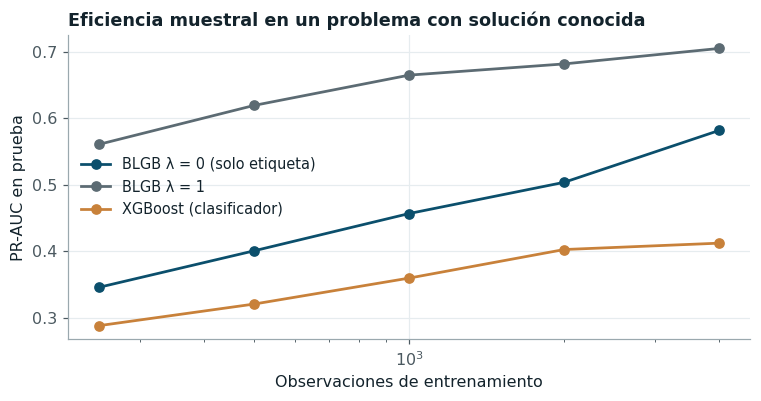

In [6]:
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier
def sintetico(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 6)); qref = np.exp(rng.normal(np.log(1000), .3, n))
    sig = .1 + .15 * (X[:, 2] > 0); z = .6 * X[:, 0] - .4 * X[:, 1] + .2 * np.sin(2 * X[:, 3]) + sig * rng.normal(size=n)
    q = qref * np.exp(z); y = ((q >= 900) & (q <= 1300)).astype(int)
    return pd.DataFrame(np.column_stack([X, qref]), columns=[*"abcdef", "qref"]), y, q
Xt, yt, _ = sintetico(5000, 99)
filas = []
for n in (250, 500, 1000, 2000, 4000):
    for s in range(5):
        X, y, q = sintetico(n, s)
        for nombre, lam in (("BLGB λ = 0 (solo etiqueta)", 0.0), ("BLGB λ = 1", 1.0)):
            m = om.BandLikelihoodBoosting(banda_inf=900, banda_sup=1300, col_referencia="qref", lambda_hibrido=lam,
                                          n_estimadores=200, tasa=.15, profundidad=3, random_state=s).fit(X, y, q_futuro=q)
            filas.append({"n": n, "modelo": nombre, "ap": average_precision_score(yt, m.predict_proba(Xt)[:, 1])})
        xg = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=.1, random_state=s, n_jobs=2).fit(X, y)
        filas.append({"n": n, "modelo": "XGBoost (clasificador)", "ap": average_precision_score(yt, xg.predict_proba(Xt)[:, 1])})
sint = pd.DataFrame(filas).groupby(["n", "modelo"]).ap.mean().unstack()
fig, ax = plt.subplots(figsize=(8, 3.6))
for c, col in zip(sint.columns, (RIO, NEU, SED)):
    ax.plot(sint.index, sint[c], "-o", color=col, label=c)
ax.set_xscale("log"); ax.set_xlabel("Observaciones de entrenamiento"); ax.set_ylabel("PR-AUC en prueba"); ax.legend()
ax.set_title("Eficiencia muestral en un problema con solución conocida")
plt.show()
ganancia = (sint["BLGB λ = 1"] - sint["XGBoost (clasificador)"])
glue("gan_250", float(ganancia.iloc[0]), display=False); glue("gan_4000", float(ganancia.iloc[-1]), display=False)

En el problema sintético la ventaja de la supervisión continua es mayor cuanto menor es la
muestra: con 250 observaciones BLGB supera al clasificador XGBoost en
{glue:text}`gan_250:.3f` puntos de PR-AUC y con 4.000, en {glue:text}`gan_4000:.3f`. El patrón
es el esperado si el beneficio proviene de la información que la etiqueta binaria descarta, y
anticipa que la ganancia en el Magdalena será relevante, porque la autocorrelación reduce el
tamaño efectivo de la muestra a una fracción de sus días.

## Estudio de ablación

In [7]:
rob = pd.read_csv(RESULTADOS / "robustez" / "robustez.csv")
ab = rob[rob.tipo == "ablacion"]
tab = ab.groupby("variante").pr_auc.agg(["mean", "std"])
base = tab.loc["completo", "mean"]
tab["Δ frente al completo"] = tab["mean"] - base
from src.stats_tests import wilcoxon_holm
piv = ab.pivot_table(index="pliegue", columns="variante", values="pr_auc")
w = wilcoxon_holm(piv, "completo")
tab = tab.join(w.set_index("modelo")[["p", "p_holm", "delta_cliff"]])
tab = tab.sort_values("mean", ascending=False)
glue("ab_lam0", float(tab.loc["sin supervisión continua (λ = 0)", "Δ frente al completo"]), display=False)
glue("ab_homo", float(tab.loc["σ constante (homocedástico)", "Δ frente al completo"]), display=False)
glue("ab_ls", float(tab.loc["sin búsqueda lineal de Armijo", "Δ frente al completo"]), display=False)
glue("ab_nll", float(tab.loc["solo verosimilitud (λ = 100)", "Δ frente al completo"]), display=False)
tab.round(4)

,mean,std,Δ frente al completo,p,p_holm,delta_cliff
variante,,,,,,
sin reajuste tras parada temprana,0.9449,0.0547,0.0021,0.9829,1.0000,-0.1111
completo,0.9428,0.0534,0.0000,NaN,NaN,NaN
sin búsqueda lineal de Armijo,0.9428,0.0534,0.0000,1.0000,1.0000,0.0000
σ constante (homocedástico),0.9421,0.0443,-0.0007,0.1331,0.3992,0.0833
solo verosimilitud (λ = 100),0.9386,0.0624,-0.0042,0.0386,0.1543,0.0556
sin supervisión continua (λ = 0),0.9203,0.0856,-0.0225,0.0134,0.0671,0.1944


La ablación retira cada componente por separado, con los hiperparámetros que la validación
anidada eligió en cada pliegue, y compara contra el modelo completo con la prueba de Wilcoxon
y corrección de Holm. Retirar la supervisión continua ($\lambda = 0$) cambia la PR-AUC media en
{glue:text}`ab_lam0:+.4f`; imponer una dispersión constante, en {glue:text}`ab_homo:+.4f`;
eliminar la búsqueda lineal, en {glue:text}`ab_ls:+.4f`; y reducir el modelo a la verosimilitud
pura ($\lambda = 100$, equivalente al enfoque de dos etapas dentro del mismo algoritmo), en
{glue:text}`ab_nll:+.4f`.

La lectura de estas cifras es nítida en un punto y matizada en los demás. La supervisión continua
es el componente que más aporta: sin ella el modelo pierde más de dos centésimas de PR-AUC y su
desviación entre bloques casi se duplica, lo que confirma que la ganancia del modelo proviene de
la información del caudal futuro que la etiqueta binaria descarta. La verosimilitud pura, en
cambio, queda cerca del modelo completo: el término de la tarea añade una mejora pequeña sobre la
regresión distribucional, coherente con el {ref}`teorema 1 <teo-propia-ref>`, según el cual
ambos términos tienen el mismo minimizador cuando la familia gaussiana es adecuada, y solo
divergen cuando está mal especificada. La dispersión heterocedástica casi no cambia la
discriminación, pero su efecto está en la calibración, que se examina en el capítulo 6. Por
último, retirar la búsqueda lineal de Armijo no altera ningún resultado: en todos los pliegues el
primer paso propuesto cumplió la condición de descenso, de modo que la búsqueda nunca redujo el
paso. Su papel es el de una salvaguarda que garantiza la monotonía del {ref}`teorema 2
<teo-descenso-ref>`, no el de una fuente de desempeño, y así se declara.